# Occlusion-Aware Frame Interpolation
**Lisa Kamenskaya · Pavel Vokhmyanin · Avdey Furmanyuk**

Can a lightweight learned blending mask improve intermediate-frame reconstruction, especially around motion boundaries and occlusion-related regions, compared with fixed or heuristic blending?

This is a controlled study of established ideas, not a new interpolation algorithm, an exact reproduction of a prior paper, or an implementation of DLSS. Two supplied exploratory notebooks provided the starting code. We corrected the data/evaluation protocol and reran the experiments from scratch.


## Related work and scope
- [Super SloMo, CVPR 2018](https://research.nvidia.com/publication/2018-06_super-slomo-high-quality-estimation-multiple-intermediate-frames-video): learned visibility maps and refined intermediate flow.
- [Softmax Splatting, CVPR 2020](https://arxiv.org/abs/2003.05534): weighted forward warping and learned image synthesis.
- [RIFE, ECCV 2022](https://arxiv.org/abs/2011.06294): directly learned intermediate flow.
- [RAFT, 2020](https://arxiv.org/abs/2003.12039): the optical-flow architecture used by our frozen motion estimator.

Our narrower experiment freezes **RAFT-small** and shares the same warps across the three primary methods. Only the blending CNN is trained. We evaluate the quality/cost trade-off and the limits of this restricted model. The residual L1/FM refiners are a separate extension, not part of the original mask-only method.


## Run this notebook
Open it from the repository root. Install the dependencies in `requirements.txt` with a compatible PyTorch/torchvision pair. The saved tables, figures, checkpoints and small demo bundle are enough for the default analysis/inference path. Full training data and caches are only needed for a rerun. Training is disabled by default; every displayed experimental number comes from a saved completed run.


In [1]:
from pathlib import Path
import json, math, time, sys, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Image, Video
get_ipython().run_line_magic('matplotlib', 'inline')
ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    raise RuntimeError('Open the notebook from the repository root.')
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device: {DEVICE}')
if DEVICE == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name()}')
RUN_TRAINING = False


Device: cuda
GPU: NVIDIA H100 80GB HBM3


## Data and leakage checks
The inputs are `im1` and `im3`; `im2` is ground truth and is never used by the deployed predictor. We pin both Hugging Face dataset revisions and preserve sequence IDs. Training candidates are filtered against **all 3,782 test sequences** by ID and decoded RGB-frame SHA-256. Exact repeated frames are also excluded across the selected train/validation pool.

Train and validation use disjoint directory-prefix groups. These prefixes are **not verified original-video IDs**; this does not guarantee absence of similar scenes. The public mirror describes its source as a subset of the official Vimeo triplet split. We additionally verify exact non-overlap ourselves.


In [2]:
data_report = json.loads((ROOT / 'artifacts/data_report.json').read_text())
display(pd.Series(data_report['counts'], name='triplets').to_frame())
print(f"Excluded candidates: {len(data_report['excluded'])}")
print(data_report['limitation'])


,triplets
train,1200
val,150
test,3782


Excluded candidates: 31
Directory prefixes are not verified original-video IDs; near-duplicate scenes are not excluded.


## Shared pipeline
1. Estimate bidirectional endpoint flow with frozen `Raft_Small_Weights.C_T_V2`.
2. Forward-splat both images by half their endpoint flow. Resolve collisions using brightness-consistency weights; use the approximate backward half-flow warp only to fill holes.
3. Blend the two midpoint warps:

\[
\hat I_t=M\odot W_0+(1-M)\odot W_1.
\]

**Fixed:** $M=0.5$. **Heuristic:** visibility/coverage cues from forward-backward consistency, with strength selected on validation. **Learned:** an 18-channel input and a three-level U-Net predict a sigmoid mask. All three use the same cached warps. Maps are transported onto the midpoint grid before use. When both warps have holes, the heuristic uses symmetric fallback blending.


In [3]:
from src.core import MaskUNet, make_warps, make_features, heuristic_mask, blend, oracle_alpha
from src.pipeline import Interpolator
from src.metrics import measure, ssim
model = MaskUNet()
print(f'Mask parameters: {sum(p.numel() for p in model.parameters()):,}')
display(model)


Mask parameters: 95,185


MaskUNet(
  (e1): Sequential(
    (0): Conv2d(18, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
  )
  (e2): Sequential(
    (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
  )
  (e3): Sequential(
    (0): Conv2d(32, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(48, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
  )
  (d2): Sequential(
    (0): Conv2d(80, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
  )
  (d1): Sequential(
    (0): Conv2d(48, 16, kernel_size=(3, 3), stride

## Training protocol
The mask uses weighted L1 reconstruction loss, emphasizing pixels where the warps disagree. We run 8,000 optimizer steps for seeds 42, 43 and 44, with batch size 8 and 192×192 crops **after full-frame warping**. We select each checkpoint by validation reconstruction in the disagreement region. Seed 42 is the primary model fixed in advance; other seeds assess robustness.

The last heuristic feature channel has fixed strength 1.0 for every model. Tuning the standalone heuristic baseline does not change the trained model's features. We cache flow/features in float16 and calculate warping, model predictions and metrics in float32. Random seeds are recorded; CUDA accumulation is not guaranteed bitwise deterministic.


In [4]:
# Optional single-GPU retraining after preparing the full data/cache.
if RUN_TRAINING:
    subprocess.run([sys.executable, 'scripts/train_mask.py', '--run', 'runs/mask_rerun',
                    '--seed', '42'], check=True)
else:
    print('Using saved completed experiments. See README for the full rerun commands.')


Using saved completed experiments. See README for the full rerun commands.


## Metrics and interpretation
We report the mean of per-image RGB PSNR, SSIM and MAE on [0,1]. SSIM uses a 7×7 uniform window and sample covariance, matching the default `skimage.metrics.structural_similarity` configuration. Regional PSNR is computed from pooled squared error and pixel counts, and must not be confused with mean per-image PSNR.

- `dis`: mean absolute disagreement of the warps exceeds 0.04.
- `occ`: proxy region from flow consistency or missing splat coverage.
- `boundary`: proxy from spatial flow variation exceeding 1 pixel.

These are method-independent diagnostic regions, **not ground-truth occlusion labels**. Paired 95% bootstrap intervals resample triplets; they do not account for unknown source-video correlations. The GT-informed oracle is only a bound on the best convex RGB blend's squared error, not a deployable method or a perceptual-quality bound.


In [5]:
primary = pd.read_csv(ROOT / 'artifacts/mask_summary.csv')
display(primary[['method', 'n_triplets', 'psnr', 'ssim', 'mae',
                 'pooled_psnr_dis', 'pooled_psnr_occ', 'pooled_psnr_boundary']].round(5))
ci = pd.read_csv(ROOT / 'artifacts/mask_paired_ci.csv')
display(ci[ci.method == 'mask_s42'].round(6))
display(pd.read_csv(ROOT / 'artifacts/mask_regional_ci.csv').round(4))
display(pd.read_csv(ROOT / 'artifacts/mask_disagreement_subgroups.csv').round(4))
print('Post-hoc border diagnostic: remove a 16-pixel border on every side.')
display(pd.read_csv(ROOT / 'artifacts/mask_interior_summary.csv').round(5))
display(pd.read_csv(ROOT / 'artifacts/mask_interior_ci.csv').round(5))


,method,n_triplets,psnr,ssim,mae,pooled_psnr_dis,pooled_psnr_occ,pooled_psnr_boundary
0,fixed,3782,32.58278,0.94730,0.01131,21.10337,24.13776,21.14820
1,oracle,3782,36.19423,0.97279,0.00708,26.34276,28.88741,25.83203
2,old_half_flow,3782,31.92909,0.94340,0.01206,20.53359,23.39655,19.96075
3,unwarped,3782,25.61271,0.75342,0.02968,17.48491,21.06641,18.00961
4,heuristic_0.5,3782,32.66427,0.94769,0.01116,21.12835,24.16964,21.00211
5,mask_s42,3782,32.91696,0.95076,0.01081,21.46733,24.61650,21.52603
6,mask_s43,3782,32.94202,0.95090,0.01080,21.50235,24.66857,21.57961
7,mask_s44,3782,32.85573,0.95048,0.01085,21.38201,24.51370,21.40232


,method,baseline,metric,delta,ci_lo,ci_hi,verdict
0,mask_s42,fixed,psnr,0.334178,0.313505,0.356105,better
1,mask_s42,fixed,ssim,0.003465,0.003317,0.003607,better
2,mask_s42,fixed,mae,-0.000503,-0.000526,-0.000481,better
9,mask_s42,heuristic_0.5,psnr,0.252688,0.233913,0.271889,better
10,mask_s42,heuristic_0.5,ssim,0.003072,0.002946,0.003209,better
11,mask_s42,heuristic_0.5,mae,-0.000348,-0.000366,-0.000330,better


,baseline,region,delta,ci_lo,ci_hi
0,fixed,dis,0.3640,0.3203,0.4073
1,fixed,occ,0.4787,0.4238,0.5349
2,fixed,boundary,0.3778,0.3237,0.4338
3,heuristic_0.5,dis,0.3390,0.3025,0.3785
4,heuristic_0.5,occ,0.4469,0.4003,0.4941
5,heuristic_0.5,boundary,0.5239,0.4698,0.5800


,quartile,n,dis_fraction_min,dis_fraction_max,delta_psnr,ci_lo,ci_hi,delta_mae
0,1,946,0.0007,0.0377,0.3667,0.3275,0.4106,-0.0002
1,2,945,0.0377,0.0646,0.4217,0.3711,0.4732,-0.0004
2,3,945,0.0646,0.0983,0.3396,0.2969,0.3837,-0.0006
3,4,946,0.0983,0.3381,0.2088,0.1749,0.2427,-0.0008


Post-hoc border diagnostic: remove a 16-pixel border on every side.


,method,n_triplets,psnr,ssim,mae,mse
0,fixed,3782,32.71521,0.94619,0.01149,0.00086
1,heuristic,3782,32.67764,0.94618,0.01147,0.00087
2,learned,3782,32.94883,0.94951,0.01107,0.00082


,metric,baseline,delta,ci_lo,ci_hi
0,psnr,fixed,0.23362,0.21542,0.25278
1,psnr,heuristic,0.27119,0.25156,0.29143
2,ssim,fixed,0.00332,0.00317,0.00348
3,ssim,heuristic,0.00333,0.00318,0.00348
4,mae,fixed,-0.00041,-0.00044,-0.00039
5,mae,heuristic,-0.00039,-0.00041,-0.00037


## Qualitative results
The figure explicitly labels an improvement case, a typical case and a failure case. The improvement example is selected at the 95th percentile of interior PSNR gain (excluding the 16-pixel border); the other examples use median and 5th-percentile full-frame gain. Labels report full-frame PSNR changes, including on crop figures. This post-hoc illustrative selection does not affect any aggregate metric or model selection.


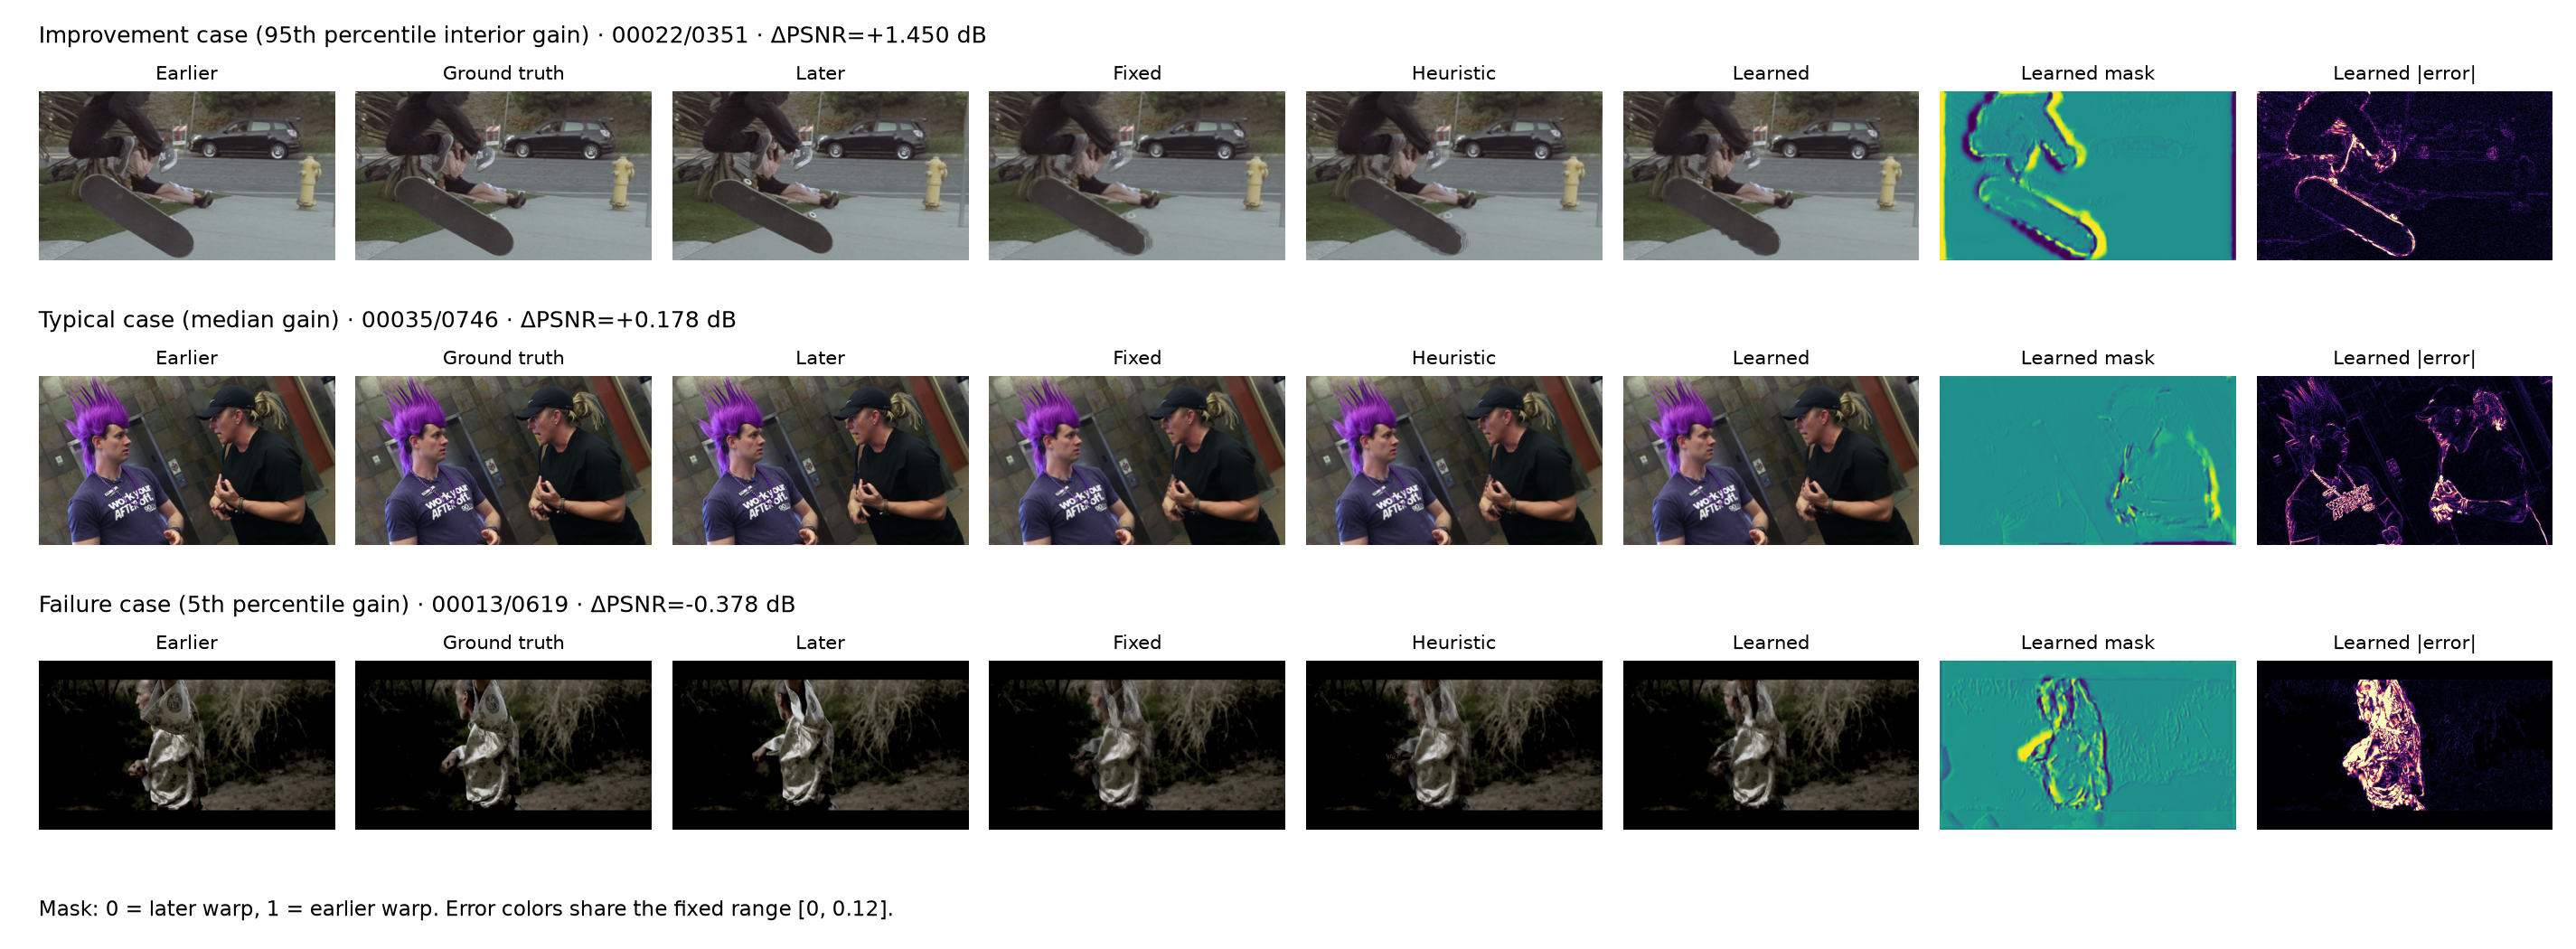

In [6]:
display(Image(filename=str(ROOT / 'artifacts/mask_examples.png')))

## Two-frame inference demo
The predictor below receives only the two endpoint images. Ground truth is loaded separately for visualization and metrics. The demo bundle contains a few held-out triplets; it is not training data.


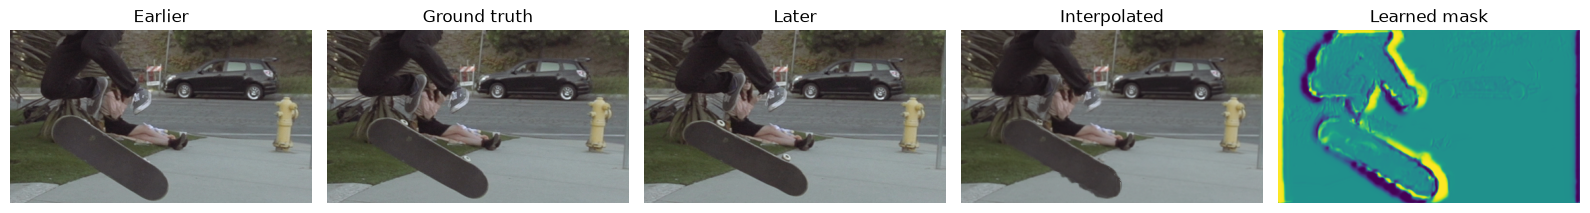

Demo PSNR: 32.931 dB
Cached evaluation PSNR: 32.936 dB


In [7]:
demo = np.load(ROOT / 'artifacts/demo_triplets.npz')
strength = json.loads((ROOT / 'artifacts/heuristic_selection.json').read_text())['strength']
interpolator = Interpolator(ROOT / 'runs/mask_s42/best.pt', DEVICE, strength)
frames = torch.from_numpy(demo['frames'][0]).float() / 255
result = interpolator(frames[0], frames[2])
fig, axes = plt.subplots(1, 5, figsize=(16, 3))
panels = [('Earlier', frames[0]), ('Ground truth', frames[1]), ('Later', frames[2]),
          ('Interpolated', result['learned'][0].cpu()), ('Learned mask', result['learned_mask'][0, 0].cpu())]
for ax, (title, image) in zip(axes, panels):
    ax.imshow(image.permute(1, 2, 0).numpy() if image.ndim == 3 else image.numpy(), cmap='viridis', vmin=0, vmax=1)
    ax.set_title(title); ax.axis('off')
plt.tight_layout(); plt.show()
pred = result['learned'][0].cpu()
mse = (pred-frames[1]).square().mean().item()
print(f'Demo PSNR: {-10*math.log10(max(mse, 1e-12)):.3f} dB')
saved = pd.read_csv(ROOT / 'artifacts/mask_metrics_per_triplet.csv')
expected = saved[(saved.key == str(demo['keys'][0])) & (saved.method == 'mask_s42')].iloc[0].psnr
print(f'Cached evaluation PSNR: {expected:.3f} dB')
assert abs(-10*math.log10(max(mse, 1e-12))-expected) < .05, 'Investigate inference/cache mismatch'


In [8]:
display(Video(str(ROOT / 'artifacts/interpolation_demo.mp4'), embed=True))

## Generative extension: residual L1 regression vs flow matching
Both refiners use the same 3.31M-parameter time-conditioned U-Net and the same frozen seed-42 mask. Their target is $(I_t-\hat I_t)/0.25$. L1 predicts the residual directly. FM learns velocity along a Gaussian-noise-to-residual path; Euler/Heun integrate it at inference.

References for this extension: [Flow Matching for Generative Modeling](https://arxiv.org/abs/2210.02747), [Classifier-Free Diffusion Guidance](https://arxiv.org/abs/2207.12598), and [Scaling Rectified Flow Transformers](https://arxiv.org/abs/2403.03206). We test these training/sampling ideas in a much smaller conditional residual model; their success elsewhere does not guarantee better reconstruction here.

We compare 12k-step L1/FM, EMA, logit-normal time sampling, condition dropout for CFG, and longer 30k training. The 30k runs start from scratch with a 30k learning-rate schedule. All refiners share cached full-frame conditioning and matching crop sampling. Temporal swapping is omitted in this extension because its cached mask conditioning is directional. Checkpoint monitoring and sampler diagnostics use two separate fixed noise streams; every sampler variant shares the same per-triplet diagnostic noise. This is an adaptation of the colleagues' code, not an exact rerun of its original training stream.


In [9]:
refiners = pd.read_csv(ROOT / 'artifacts/refiner_test_summary.csv')
display(refiners[['method', 'n_triplets', 'psnr', 'ssim', 'mae', 'lpips', 'pooled_psnr_dis']].round(5))
diagnostics = pd.read_csv(ROOT / 'artifacts/refiner_validation_summary.csv')
display(diagnostics[['experiment', 'checkpoint_step', 'psnr', 'ssim', 'lpips',
                     'pooled_psnr_dis', 'refiner_ms_per_triplet']].round(5))
display(pd.read_csv(ROOT / 'artifacts/refiner_paired_ci.csv').round(5))


,method,n_triplets,psnr,ssim,mae,lpips,pooled_psnr_dis
0,l1,3782,33.40541,0.95499,0.01024,0.03416,21.92624
1,l1_dis,3782,33.19153,0.95232,0.01062,0.04028,21.92624
2,learned_cached_reference,3782,32.91684,0.95077,0.01081,0.04126,21.46731
3,fm,3782,32.03058,0.94003,0.01227,0.05126,20.89672
4,fm_dis,3782,32.39815,0.94627,0.01127,0.04530,20.89672
5,fm_mean4,3782,32.70363,0.94775,0.01133,0.03743,21.29897
6,fm_mean4_dis,3782,32.76127,0.94911,0.01098,0.04057,21.29897
7,selected_fm,3782,32.03058,0.94003,0.01227,0.05126,20.89672
8,selected_fm_dis,3782,32.39815,0.94627,0.01127,0.04530,20.89672


,experiment,checkpoint_step,psnr,ssim,lpips,pooled_psnr_dis,refiner_ms_per_triplet
0,val_cfg_w2,4000,29.31976,0.91936,0.07470,17.90937,103.50180
1,val_cfg_w3,4000,27.64134,0.90315,0.09720,16.16547,101.55590
2,val_fm_30k,2000,31.77626,0.93579,0.05891,20.99259,57.25546
3,val_fm_ema,12000,31.86437,0.94301,0.04299,20.50849,56.00825
4,val_fm_ema_lognormal,4000,31.13252,0.93195,0.05502,20.02432,56.85622
5,val_fm_ema_lognormal_30k,22000,31.76033,0.94300,0.03677,20.22034,55.19748
6,val_fm_ema_lognormal_cfg,4000,31.12973,0.93073,0.06193,20.15487,56.63625
7,val_fm_euler100,2000,31.66650,0.93455,0.05829,20.95662,244.89551
8,val_fm_euler20,2000,32.02769,0.94160,0.05041,21.11604,55.93680
9,val_fm_euler50,2000,31.71580,0.93695,0.05775,20.95267,128.49178


,experiment,metric,delta,ci_lo,ci_hi,verdict
0,test_l1,psnr,0.48858,0.47331,0.50416,better
1,test_l1,ssim,0.00421,0.00408,0.00434,better
2,test_l1,mae,-0.00057,-0.00059,-0.00055,better
3,test_l1,lpips,-0.00710,-0.00739,-0.00681,better
4,test_l1,lpips_window,-0.00229,-0.00278,-0.00179,better
5,test_fm,psnr,-0.88626,-0.90843,-0.86366,worse
6,test_fm,ssim,-0.01074,-0.01092,-0.01055,worse
7,test_fm,mae,0.00146,0.00144,0.00148,worse
8,test_fm,lpips,0.01000,0.00942,0.01056,worse
9,test_fm,lpips_window,0.01329,0.01237,0.01426,worse


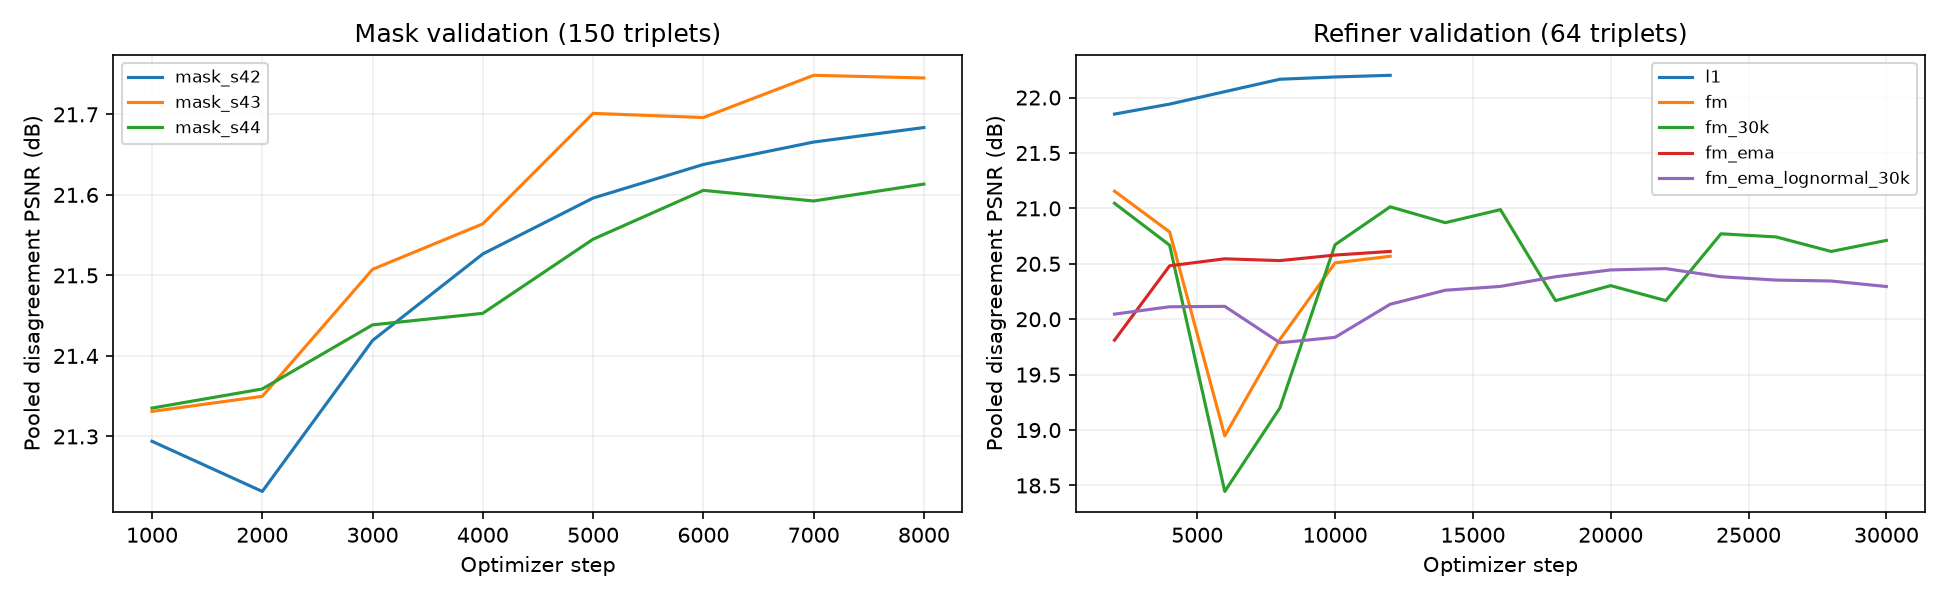

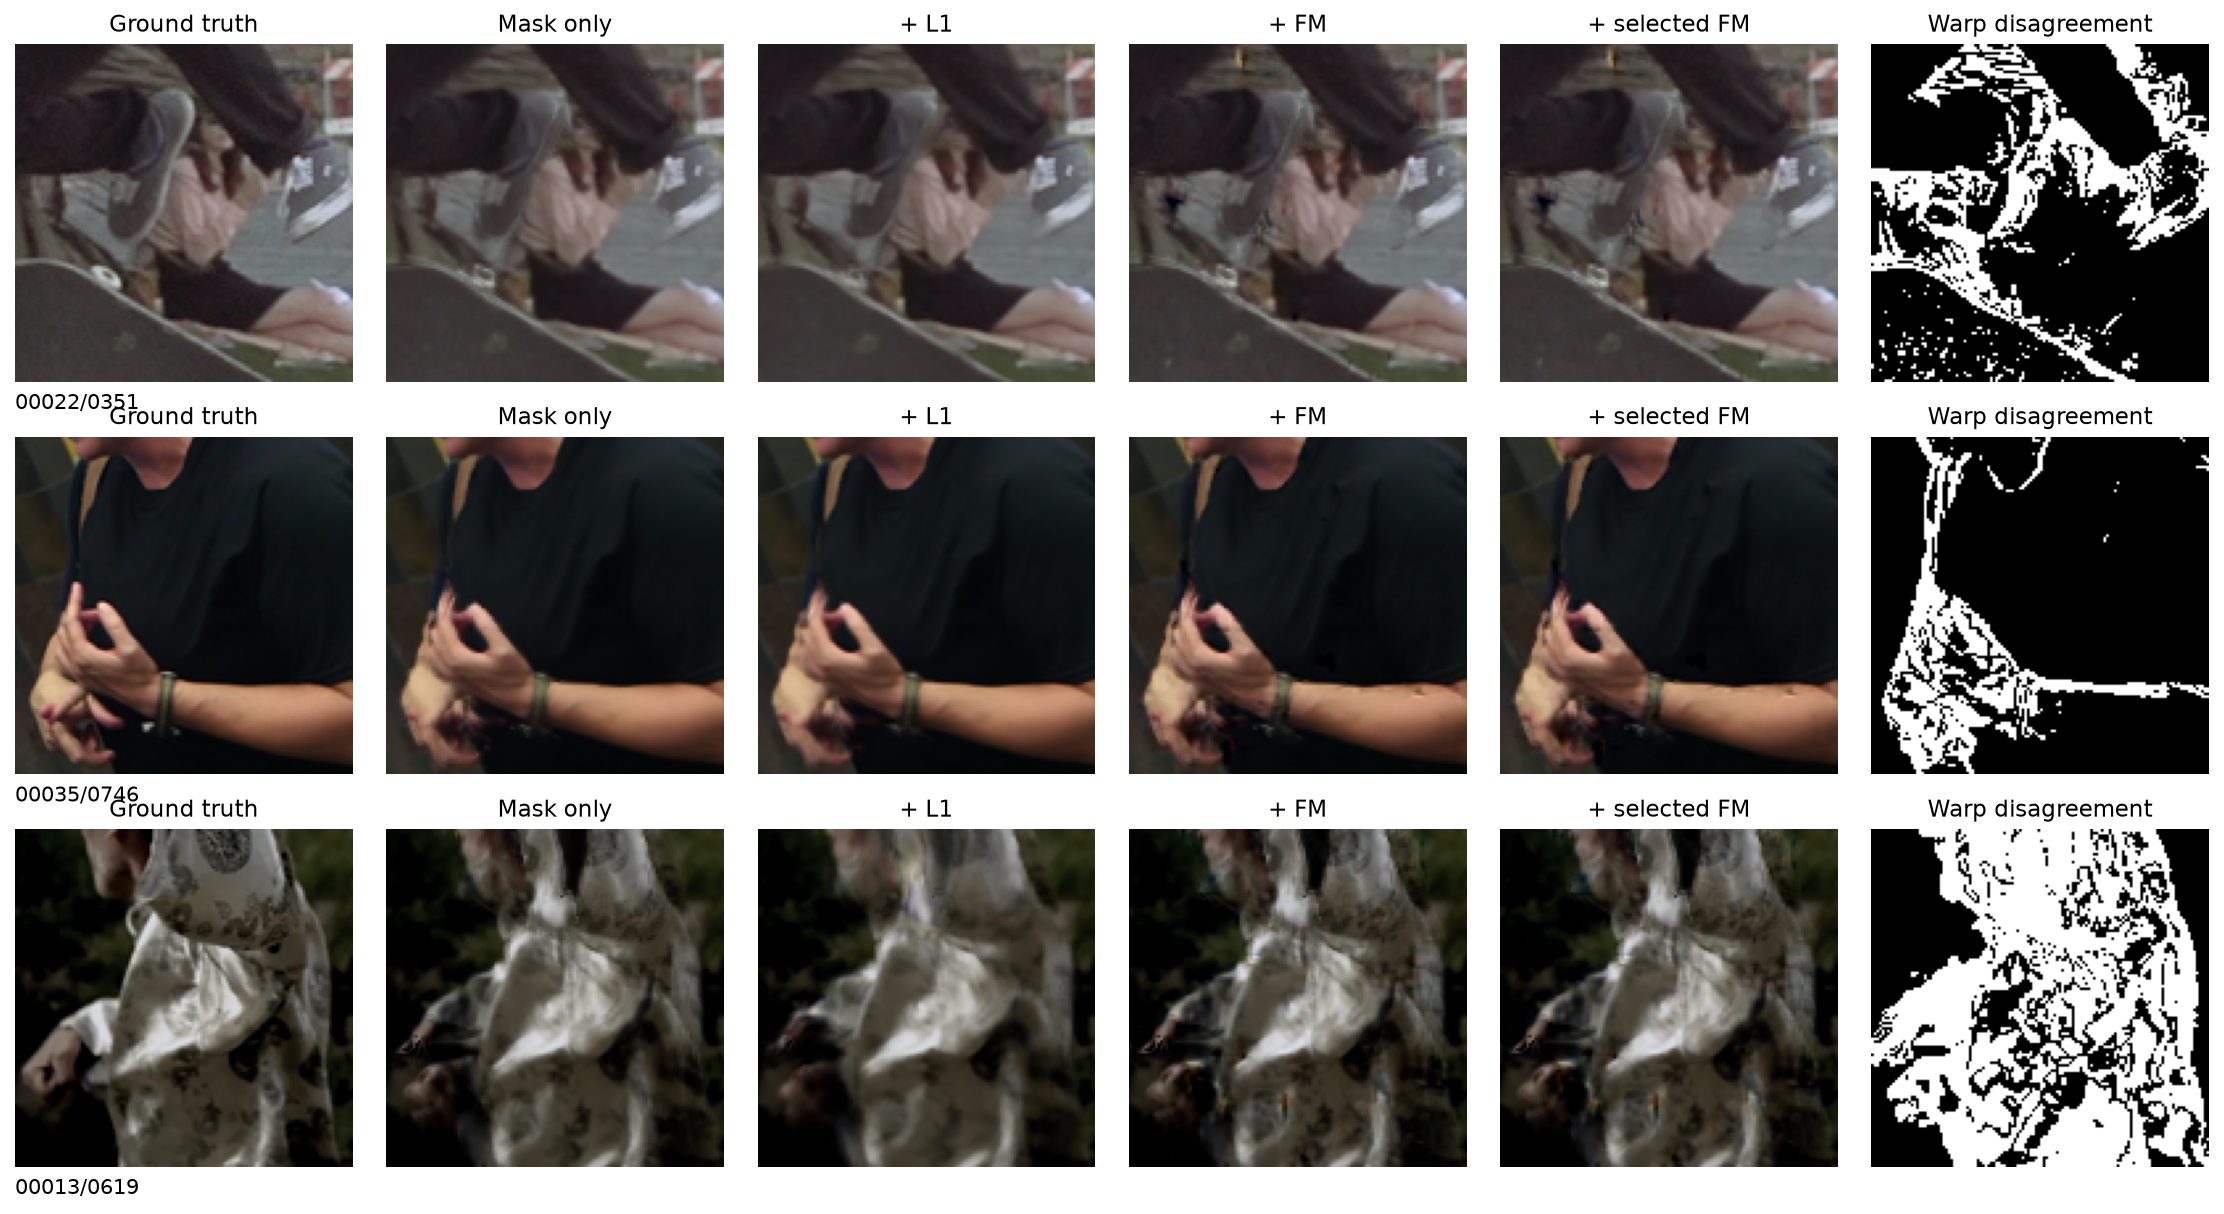

In [10]:
display(Image(filename=str(ROOT / 'artifacts/learning_curves.png')))
display(Image(filename=str(ROOT / 'artifacts/refiner_examples.png')))

## Runtime and limitations
The small mask adds computation on top of two RAFT passes. FM additionally requires many refiner evaluations; a better ODE solver is not free. Runtime results include the hardware, resolution, batch size and measured scope. The 1.2k-triplet training subset and single refiner seed limit conclusions about scaling and stability. A mask cannot create colors/details outside the convex blend of its two warped inputs.


In [11]:
runtime = json.loads((ROOT / 'artifacts/runtime.json').read_text())
display(pd.Series(runtime).to_frame('value'))
print((ROOT / 'artifacts/conclusions.txt').read_text())


,value
gpu,NVIDIA H100 80GB HBM3
resolution,256x448
batch_size,1
repetitions,30
warmup,5
torch,2.14.1+cu126
precision,fp32 with fp16 flow/features round-trip; TF32 ...
flow_warp_features_median_ms,54.365838
mask_and_blend_median_ms,0.839922
full_pipeline_median_ms,56.039035


The primary seed-42 learned mask improves mean test PSNR by +0.334 dB over fixed blending (paired triplet-bootstrap 95% CI [+0.314, +0.356]) and by +0.253 dB over the validation-selected heuristic.
SSIM changes from 0.94730 to 0.95076; MAE changes from 0.011315 to 0.010812.
All three mask seeds improve mean test PSNR over fixed blending. Regional results support benefits in the chosen disagreement/occlusion-related proxies, but these are not ground-truth occlusion annotations.
Gains are positive in all four warp-disagreement quartiles, but they are not monotonic: the lowest-disagreement quartile gains +0.367 dB and the highest gains +0.209 dB. Larger absolute MAE reductions in difficult examples do not imply larger dB gains. This is consistent with limits of blending under imperfect warping, but does not establish the cause of each failure.
Post-hoc border diagnostic: after removing a 16-pixel border on all sides, the learned-mask gain over fixed blending is +0.234 dB (paired 95% CI [+

## Reproducibility and provenance
`src/` contains shared model/inference code; `scripts/` contains data preparation, training, evaluation and report generation. `runs/` preserves model configurations, histories and best checkpoints; `artifacts/` preserves per-triplet metrics and selection decisions. The two original notebooks are archived unchanged with SHA-256 checksums. See `README.md` for full commands and the distinction between original exploratory results and the corrected rerun.
